# Assignment 3 - Coding
### Andres Arias Medina
### Z23987588

### I used Claude to help me generate some markdowns with mathematical expressions

## 11. Gaussian MLE
### Setup

In [1]:
import numpy as np  
from scipy.stats import norm  # Gaussian distribution
import matplotlib.pyplot as plt  
np.random.seed(42)  # fix the random seed so the results are reproducible

### 11. 1)-1 Generate data from a Gaussian distribution
I choose the true parameters of the oracle distribution: mean `true_mean = 5.0`, standard deviation `true_std = 2.0` and `no_data = 500`

In [2]:
true_mean = 5.0  # mean of the true Gaussian
true_std = 2.0  # standard deviation of the true Gaussian
no_data = 500  # number of data points (> 100)
orig_data = np.random.normal(true_mean, true_std, no_data)  # draw no_data samples from N(true_mean, true_std^2)
print(orig_data[:10])

[5.99342831 4.7234714  6.29537708 8.04605971 4.53169325 4.53172609
 8.15842563 6.53486946 4.06105123 6.08512009]


### 11. 1)-2 MLE estimation of the mean and standard deviation
Maximizing the Gaussian log-likelihood
$\log L(\mu,\sigma^2) = -\frac{n}{2}\log(2\pi) - \frac{n}{2}\log\sigma^2 - \frac{1}{2\sigma^2}\sum_i (x_i-\mu)^2$
gives the closed form estimates

$$\hat\mu_{MLE} = \frac{1}{n}\sum_{i=1}^n x_i, \qquad \hat\sigma^2_{MLE} = \frac{1}{n}\sum_{i=1}^n (x_i-\hat\mu_{MLE})^2$$

The code computes both formulas explicitly (sum divided by n, so the MLE variance uses 1/n and not 1/(n−1)), takes the square root to get the standard deviation, checks them against `np.mean` and `np.std` (whose default `ddof=0` is exactly the MLE), and prints the true and estimated values.

In [3]:
n = len(orig_data)  # number of observations

mle_mean = np.sum(orig_data) / n  # MLE of the mean
mle_var = np.sum((orig_data - mle_mean) ** 2) / n  # MLE of the variance | average squared deviation (1/n, biased)
mle_std = np.sqrt(mle_var)  # MLE of the standard deviation

assert np.isclose(mle_mean, np.mean(orig_data))  # sanity check against numpy mean
assert np.isclose(mle_std, np.std(orig_data, ddof=0))  # sanity check against numpy std (ddof=0 is the MLE)

print(f"true_mean = {true_mean:.4f}, mle_mean = {mle_mean:.4f}")  # true vs estimated mean
print(f"true_std  = {true_std:.4f}, mle_std  = {mle_std:.4f}")  # true vs estimated std

true_mean = 5.0000, mle_mean = 5.0137
true_std  = 2.0000, mle_std  = 1.9605


### Visualization grid (given code)
Create 500 evenly spaced x values covering the data range (with a margin of 1 on each side) and evaluate the density of the true Gaussian and of the Gaussian with the MLE parameters on that grid.

In [4]:
x = np.linspace(min(orig_data) - 1, max(orig_data) + 1, no_data)
true_pdf = norm.pdf(x, true_mean, true_std)
mle_pdf = norm.pdf(x, mle_mean, mle_std)

### 11. 1)-3 Plot the true pdf and the MLE pdf together
I draw the true density as a dashed line and the MLE density as a solid line on the same axes. A normalized histogram of `orig_data` is added in the background so I can see that both curves describe the observed data. If the MLE is good, the two curves almost overlap.

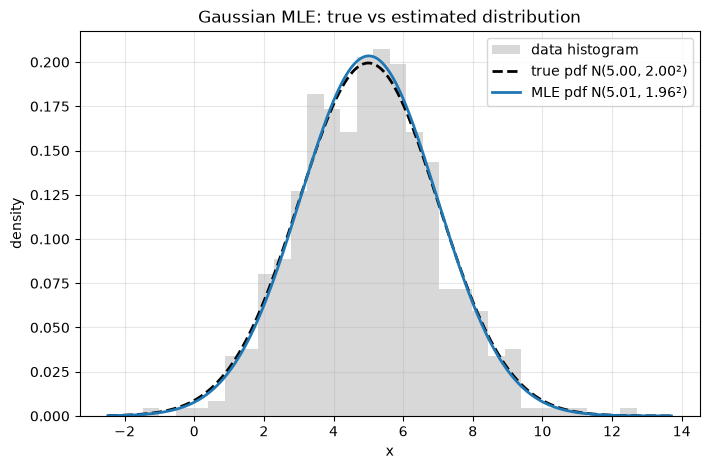

In [5]:
plt.figure(figsize=(8, 5))  # create the figure
plt.hist(orig_data, bins=30, density=True, alpha=0.3, color='gray', label='data histogram')  # normalized histogram of the samples
plt.plot(x, true_pdf, linestyle='--', linewidth=2, color='black', label=f'true pdf N({true_mean:.2f}, {true_std:.2f}²)')  # true density, dashed
plt.plot(x, mle_pdf, linewidth=2, color='tab:blue', label=f'MLE pdf N({mle_mean:.2f}, {mle_std:.2f}²)')  # MLE density, solid
plt.xlabel('x')  # x-axis label
plt.ylabel('density')  # y-axis label
plt.title('Gaussian MLE: true vs estimated distribution')  # plot title
plt.legend()  # show the legend
plt.grid(alpha=0.3)  # light grid for readability
plt.show()  # render the plot

## 12. Bayes Network, Gibbs sampling
### Setup: libraries and CPTs (given code)
Network: C → S, C → R, S → W, R → W. The dictionaries encode the CPTs with the convention

* `P_C[c] = P(C=c)`
* `P_S_given_C[(c, s)] = P(S=s | C=c)`
* `P_R_given_C[(c, r)] = P(R=r | C=c)`
* `P_W_given_S_R[(s, r, w)] = P(W=w | S=s, R=r)`

In [6]:
import numpy as np  # numerical library
import random  # Python random number generator (used for sampling)
random.seed(0)  # fix the seed so the Gibbs chain is reproducible

P_C = {0: 0.4, 1: 0.6}  # P(C=c)

P_S_given_C = {  # P(S=s | C=c), key = (c, s)
    (0, 0): 0.4, (0, 1): 0.6,
    (1, 0): 0.2, (1, 1): 0.8
}

P_R_given_C = {  # P(R=r | C=c), key = (c, r)
    (0, 0): 0.8, (0, 1): 0.2,
    (1, 0): 0.2, (1, 1): 0.8
}

P_W_given_S_R = {  # P(W=w | S=s, R=r), key = (s, r, w)
    (0, 0, 0): 0.9,  (0, 0, 1): 0.1,
    (0, 1, 0): 0.1,  (0, 1, 1): 0.9,
    (1, 0, 0): 0.1,  (1, 0, 1): 0.9,
    (1, 1, 0): 0.01, (1, 1, 1): 0.99
}

### 12.1 `sample_C(s, r, w)`
In Gibbs sampling, C is sampled given its Markov blanket. C has no parents, its children are S and R, so only the CPTs that contain C remain:

P(C=c | S, R, W) ∝ P(C=c) · P(S=s | C=c) · P(R=r | C=c)

P(W | S, R) does not contain C, so it is the same for C=0 and C=1 and cancels in the normalization.

The function:
1. computes the unnormalized value for C=0 and for C=1 with the formula above,
2. divides both by their sum to obtain P(C=0 | S,R,W) and P(C=1 | S,R,W),
3. draws a uniform random number in [0, 1); if it is smaller than P(C=1 | S,R,W) it returns C=1, otherwise C=0.

In [7]:
# Sampling function for a variable given Markov blanket
def sample_C(s, r, w):
    p_c0 = P_C[0] * P_S_given_C[(0, s)] * P_R_given_C[(0, r)]  # unnormalized P(C=0 | S, R, W)
    p_c1 = P_C[1] * P_S_given_C[(1, s)] * P_R_given_C[(1, r)]  # unnormalized P(C=1 | S, R, W)
    total = p_c0 + p_c1  # normalization constant

    p_c0 = p_c0 / total  # P(C=0 | S, R, W)
    p_c1 = p_c1 / total  # P(C=1 | S, R, W)
    
    if random.random() < p_c1:  # draw a uniform number and compare with P(C=1 | S, R, W)
        return 1  # C = 1 is sampled with probability p_c1
    return 0  # otherwise C = 0 is sampled

### 12.2 `sample_S(c, r, w)`
The Markov blanket of S is its parent C, its child W and W's other parent R. The CPTs that contain S are P(S | C) and P(W | S, R):

P(S=s | C, R, W) ∝ P(S=s | C=c) · P(W=w | S=s, R=r)

P(C) and P(R | C) do not contain S and cancel.

The function computes the unnormalized values for S=0 and S=1, normalizes them to obtain P(S=0 | C,R,W) and P(S=1 | C,R,W), and returns S=1 with probability P(S=1 | C,R,W), otherwise S=0.

In [8]:
def sample_S(c, r, w):
    p_s0 = P_S_given_C[(c, 0)] * P_W_given_S_R[(0, r, w)]  # unnormalized P(S=0 | C, R, W)
    p_s1 = P_S_given_C[(c, 1)] * P_W_given_S_R[(1, r, w)]  # unnormalized P(S=1 | C, R, W)
    total = p_s0 + p_s1  # normalization constant

    p_s0 = p_s0 / total  # P(S=0 | C, R, W)
    p_s1 = p_s1 / total  # P(S=1 | C, R, W)
    
    if random.random() < p_s1:  # draw a uniform number and compare with P(S=1 | C, R, W)
        return 1  # S = 1 is sampled with probability p_s1
    return 0  # otherwise S = 0 is sampled

### 12.3 `sample_R(c, s, w)`
By symmetry with S, the Markov blanket of R is its parent C, its child W and W's other parent S. The CPTs that contain R are P(R | C) and P(W | S, R):

P(R=r | C, S, W) ∝ P(R=r | C=c) · P(W=w | S=s, R=r)

The function computes the unnormalized values for R=0 and R=1, normalizes them to obtain P(R=0 | C,S,W) and P(R=1 | C,S,W), and returns R=1 with probability P(R=1 | C,S,W), otherwise R=0.

In [9]:
def sample_R(c, s, w):
    p_r0 = P_R_given_C[(c, 0)] * P_W_given_S_R[(s, 0, w)]  # unnormalized P(R=0 | C, S, W)
    p_r1 = P_R_given_C[(c, 1)] * P_W_given_S_R[(s, 1, w)]  # unnormalized P(R=1 | C, S, W)
    total = p_r0 + p_r1  # normalization constant

    p_r0 = p_r0 / total  # P(R=0 | C, S, W)
    p_r1 = p_r1 / total  # P(R=1 | C, S, W)
    
    if random.random() < p_r1:  # draw a uniform number and compare with P(R=1 | C, S, W)
        return 1  # R = 1 is sampled with probability p_r1
    return 0  # otherwise R = 0 is sampled

### Given code: Gibbs sampling settings

In [10]:
# Gibbs Sampling
# w=1 (evidence)
evidence_w = 1  # observed evidence W = 1
iterations = 600  # number of Gibbs sampling iterations

""" Perform Gibbs Sampling to estimate P(C | W=1) """
samples = []  # list that stores the sampled values of C

### 12.4 Random initialization
Gibbs sampling starts from an arbitrary state consistent with the evidence. The non-evidence variables C, S and R are initialized randomly to 0 or 1 with `random.randint(0, 1)`, and W is set to the evidence value 1.

In [11]:
# Initialize randomly
c = random.randint(0, 1)  # random initial value of C (0 or 1)
s = random.randint(0, 1)  # random initial value of S (0 or 1)
r = random.randint(0, 1)  # random initial value of R (0 or 1)

w = evidence_w  # W is fixed to the evidence, w = 1
print(f"Initial state: C={c}, S={s}, R={r}, W={w}")  # show the initial state

Initial state: C=1, S=1, R=0, W=1


### 12.5 Gibbs sampling loop
In each iteration I resample C, S and R in this order. Each variable is sampled given the current values of the other variables, so the new value of C is used immediately to sample S and the new values of C and S are used to sample R. W is never resampled because it is evidence. At the end of each iteration the value of C is appended to `samples`.

In [12]:
for i in range(iterations):
    c = sample_C(s, r, w)  # sample C given the current S, R, W
    s = sample_S(c, r, w)  # sample S given the new C and the current R, W
    r = sample_R(c, s, w)  # sample R given the new C, S and W

    samples.append(c)  # append the value of C into samples

### 12.6 Compute P(C=1 | W=1)
Each entry of `samples` is 0 or 1, so the fraction of samples where C=1 is the Gibbs estimate of P(C=1 | W=1): count the samples equal to 1 and divide by the total number of samples.

In [13]:
# Compute P(C=1 | W=1)
count_c1 = samples.count(1)  # number of samples where C = 1
p_c1_given_w1 = count_c1 / len(samples)  # fraction of samples with C = 1
print(f"P(C=1 | W=1) = {p_c1_given_w1:.4f}")  # print the estimated probability

P(C=1 | W=1) = 0.6800
